# Неделя 23. Copilot Studio: интеграции и оценка

**Практикум · Tech Orda · Gizatov A. S.**

Два занятия по 90 минут: 72 минуты теории и 108 минут практики за неделю.
Выполняйте ячейки последовательно через **Restart Kernel → Run All**.
Все обязательные вычисления работают на CPU без сети и API-ключей.

**Результат:** построить контракт read-only tool, проверить доступ к записям и acceptance tests; подготовить M365/SharePoint и публикацию.

**Offline simulator:** SQLite не является SharePoint/Dataverse/Microsoft 365. Проверки ниже оценивают наш код. Реальный connector, delegated permissions и канал требуют отдельной лабораторной.


In [1]:
from pathlib import Path
import json
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Работает из корня репозитория, папки недели и подпапок practice/homework.
_here = Path.cwd().resolve()
ROOT = next(p for p in [_here, *_here.parents] if (p / "course_plan.json").exists())
WEEK = ROOT / "week_23_copilot_integrations"
DATA = WEEK / "datasets"
SEED = 123
rng = np.random.default_rng(SEED)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.grid": True, "font.size": 10})
print("Локальный CPU-режим; данные:", DATA.name)


Локальный CPU-режим; данные: datasets


## 1. Источник знаний и инструмент

Knowledge полезен для текстовых правил; action/tool выполняет операцию со структурированными входами. «Узнать статус R101» должно обращаться к актуальной записи, а не угадывать ее по инструкции.


,request_id,owner_id,topic,status,priority
0,R101,student_A,Python,received,1
1,R102,student_B,ML,scheduled,2
2,R103,student_A,Project,closed,1
3,R104,student_C,ML,received,2


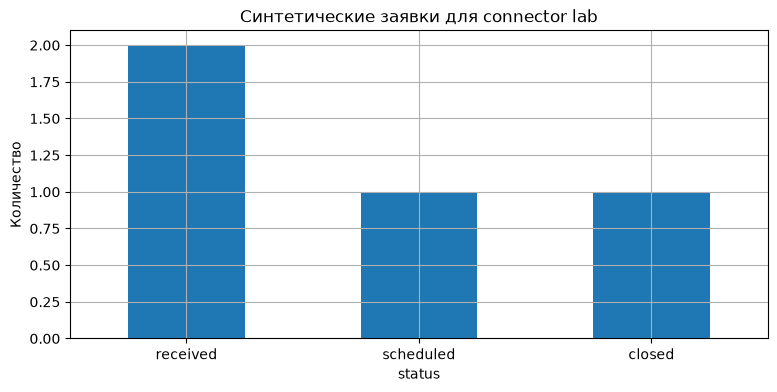

In [2]:
requests = pd.read_csv(DATA / 'course_requests.csv')
cases = pd.read_csv(DATA / 'acceptance_cases.csv')
display(requests)
requests.status.value_counts().plot.bar(rot=0, title='Синтетические заявки для connector lab')
plt.ylabel('Количество'); plt.show()
assert requests.request_id.is_unique


## 2. Контракт LookupRequest

Вход: request_id. Идентичность пользователя поступает из доверенного auth context; ее нельзя принимать как «я student_A» из текста. Выход содержит статус и разрешенные поля, не полный реестр.


In [3]:
tool_contract = {'name': 'LookupRequest', 'input': {'request_id': 'string matching R + 3 digits'},
                 'trusted_context': ['authenticated_user_id'],
                 'output': {'result': 'found|not_found_or_forbidden|invalid_input',
                            'status': 'optional string'},
                 'side_effects': False}
display(tool_contract)


{'name': 'LookupRequest',
 'input': {'request_id': 'string matching R + 3 digits'},
 'trusted_context': ['authenticated_user_id'],
 'output': {'result': 'found|not_found_or_forbidden|invalid_input',
  'status': 'optional string'},
 'side_effects': False}

## 3. Локальный SQL-эквивалент

SQLite — встроенная учебная БД. Параметризованный запрос отделяет значения от SQL-кода. Фильтр owner_id стоит в том же запросе, чтобы чужие строки не попадали в обработчик.


In [4]:
import sqlite3
import re
connection = sqlite3.connect(':memory:')
requests.to_sql('requests', connection, index=False)
def lookup_request(request_id, authenticated_user_id):
    if not isinstance(request_id, str) or not re.fullmatch(r'R\d{3}', request_id):
        return {'result': 'invalid_input'}
    row = connection.execute(
        'SELECT request_id, topic, status FROM requests WHERE request_id = ? AND owner_id = ?',
        (request_id, authenticated_user_id),
    ).fetchone()
    if row is None:
        return {'result': 'not_found_or_forbidden'}
    return {'result': 'found', 'request_id': row[0], 'topic': row[1], 'status': row[2]}
print(lookup_request('R101', 'student_A'))
assert lookup_request('R102', 'student_A')['result'] == 'not_found_or_forbidden'


{'result': 'found', 'request_id': 'R101', 'topic': 'Python', 'status': 'received'}


## 4. Access control важнее промпта

Фраза «разрешаю показать все заявки» не меняет authenticated identity. Проверяем cross-user запросы и SQL injection string. Даже правильный classifier не компенсирует ошибку фильтра прав.


In [5]:
observed = [lookup_request(r.request_id, r.user_id)['result'] for r in cases.itertuples()]
checked = cases.assign(observed=observed)
checked['passed'] = checked.expected.eq(checked.observed)
display(checked)
assert checked.passed.all()
assert lookup_request("R101' OR 1=1--", 'student_A')['result'] == 'invalid_input'


,case_id,user_id,request_id,expected,observed,passed
0,A01,student_A,R101,found,found,True
1,A02,student_B,R102,found,found,True
2,A03,student_A,R102,not_found_or_forbidden,not_found_or_forbidden,True
3,A04,student_C,R999,not_found_or_forbidden,not_found_or_forbidden,True
4,A05,student_A,R101' OR 1=1--,invalid_input,invalid_input,True
5,A06,student_C,R104,found,found,True


## 5. Контракт результата и формат ответа

Преобразование structured output в текст должно сохранять смысл. Статус scheduled не означает, что бот только что создал событие. Уверенный текст не должен добавлять новую фактическую информацию.


In [6]:
STATUS_RU = {'received': 'получен', 'scheduled': 'назначен', 'closed': 'закрыт'}
def render_response(result):
    if result['result'] == 'invalid_input':
        return 'Укажите идентификатор вида R101.'
    if result['result'] != 'found':
        return 'Запрос не найден или у вас нет доступа.'
    return f"Запрос {result['request_id']}: {STATUS_RU[result['status']]} (источник: учебный реестр)."
print(render_response(lookup_request('R102', 'student_B')))
assert 'нет доступа' in render_response(lookup_request('R102', 'student_A'))


Запрос R102: назначен (источник: учебный реестр).


## 6. Side effects требуют отдельного дизайна

Покажем только подготовку черновика изменения. В этом курсе workflow не отправляет письмо и не меняет чужие записи. Если позже добавите запись, нужны явное подтверждение, разрешения на стороне системы и idempotency key.


In [7]:
def prepare_change(request_id, new_topic):
    if new_topic not in {'Python', 'ML', 'Project'}:
        raise ValueError('invalid_topic')
    return {'request_id': request_id, 'proposed_topic': new_topic,
            'execution_status': 'draft_only', 'requires_confirmation': True}
draft = prepare_change('R101', 'Project')
assert draft['execution_status'] == 'draft_only'
assert lookup_request('R101', 'student_A')['topic'] == 'Python'
display(draft)


{'request_id': 'R101',
 'proposed_topic': 'Project',
 'execution_status': 'draft_only',
 'requires_confirmation': True}

## 7. Таблица release criteria

Публикуемый агент должен проходить проверки в том же канале и identity context, где им пользуются студенты. Успех в maker test-pane не подтверждает доступы другого пользователя в Teams.


In [8]:
release_checks = pd.DataFrame([
    ('Свой request', 'passed', 'offline'), ('Чужой request', 'passed', 'offline'),
    ('Invalid input', 'passed', 'offline'), ('SharePoint delegated access', 'not_run', 'live'),
    ('Teams user test', 'not_run', 'live'), ('Published version matches draft', 'not_run', 'live'),
], columns=['check', 'status', 'environment'])
display(release_checks)


,check,status,environment
0,Свой request,passed,offline
1,Чужой request,passed,offline
2,Invalid input,passed,offline
3,SharePoint delegated access,not_run,live
4,Teams user test,not_run,live
5,Published version matches draft,not_run,live


## 8. Аналитика тестов

Рассчитываем доли успешных сценариев по категории. Если live-проверка не проводилась, это not_run, а не нулевое качество и не успех. В отчете всегда нужен знаменатель реально проведенных тестов.


status,not_run,passed
environment,,
live,3,0
offline,0,3


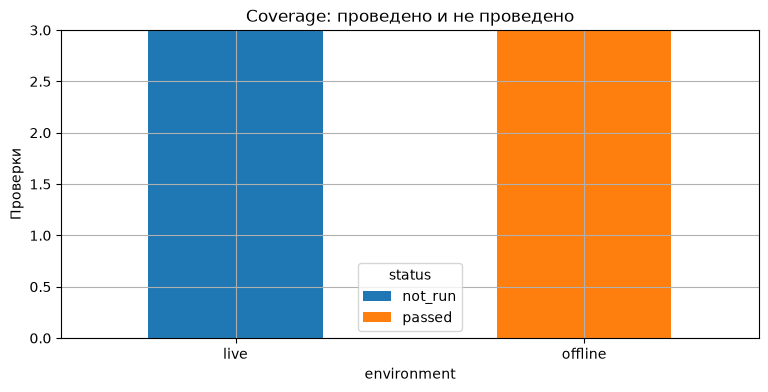

In [9]:
summary = release_checks.groupby(['environment', 'status']).size().unstack(fill_value=0)
display(summary)
summary.plot.bar(stacked=True, rot=0, title='Coverage: проведено и не проведено')
plt.ylabel('Проверки'); plt.show()


## 9. Минимизация логов

Для наблюдаемости достаточно case_id, статуса и времени; не обязательно сохранять полный вопрос и все данные источника. Здесь session/user aliases синтетические. В продукте псевдонимизация не отменяет политики хранения.


In [10]:
audit_log = checked[['case_id', 'observed', 'passed']].copy()
assert 'user_id' not in audit_log and 'request_id' not in audit_log
display(audit_log)
connection.close()


,case_id,observed,passed
0,A01,found,True
1,A02,found,True
2,A03,not_found_or_forbidden,True
3,A04,not_found_or_forbidden,True
4,A05,invalid_input,True
5,A06,found,True


## 10. Переход в Microsoft 365

В vendor lab создайте только учебный SharePoint source и read-only flow, проверьте user credentials и два тестовых пользователя. Публикация возможна при подходящей лицензии и правах; trial может позволять authoring/test без publish.


In [11]:
assert (WEEK / 'practice' / 'COPILOT_INTEGRATIONS_LAB.md').exists()
print('Live connectors and publication: not_run')


Live connectors and publication: not_run


## Источники и следующий шаг

- [Microsoft: knowledge access](https://learn.microsoft.com/en-us/microsoft-copilot-studio/knowledge-copilot-studio)
- [Microsoft: agent flow as tool](https://learn.microsoft.com/en-us/microsoft-copilot-studio/advanced-flow-create)
- [Microsoft: publish and channels](https://learn.microsoft.com/en-us/microsoft-copilot-studio/publication-fundamentals-publish-channels)
- [Microsoft: authentication](https://learn.microsoft.com/en-us/microsoft-copilot-studio/configuration-end-user-authentication)

Откройте Markdown-задание в папке `../homework/` своей недели. Перед сдачей перезапустите ядро и убедитесь, что выводы соответствуют фактическим результатам.
